# Gini ou entropie : derrière les branches de nos arbres de décision
**Intechnia — Notebook expérimental**

Comprendre les critères de découpage des arbres de classification et leur impact, au-delà de leur simple optimisation par GridSearchCV. Comparaison descriptive, sans revendication de supériorité générale. Toutes les figures et les données de résultats sont exportées. Les conclusions sont conditionnelles au protocole.

In [1]:
from pathlib import Path
from time import perf_counter
from importlib.util import find_spec
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer, load_wine, load_digits, make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, _classes
from threadpoolctl import threadpool_limits

SEED, N_SPLITS, N_REPEATS, N_TREES = 42, 5, 3, 100
CRITERIA = ('gini', 'entropy')
MODELS = ('Arbre', 'Forêt')
FIGURES, RESULTS = Path('figures'), Path('results')
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

def save_table(df, name):
    df.to_csv(RESULTS / f'{name}.csv', index=False)

def save_figure(fig, name):
    for ext in ('png', 'svg'):
        fig.savefig(FIGURES / f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.titleweight':'bold', 'figure.dpi':110, 'savefig.dpi':180})
COLORS = {'gini':'#333333', 'entropy':'#a45a36'}
cpu = platform.processor() or platform.machine()
if Path('/proc/cpuinfo').exists():
    cpu = next((s.split(':',1)[1].strip() for s in Path('/proc/cpuinfo').read_text().splitlines()
                if s.startswith('model name')), cpu)
metadata = pd.DataFrame([{'python':sys.version.split()[0], 'sklearn':sklearn.__version__,
    'numpy':np.__version__, 'pandas':pd.__version__, 'matplotlib':matplotlib.__version__,
    'platform':platform.platform(), 'cpu':cpu, 'seed':SEED, 'folds':N_SPLITS,
    'repeats':N_REPEATS, 'n_trees':N_TREES}])
save_table(metadata,'environment')
display(metadata.T)

,0
python,3.13.5
sklearn,1.8.0
numpy,2.3.5
pandas,2.2.3
matplotlib,3.10.8
platform,Linux-6.18.57-x86_64-with-glibc2.41
cpu,INTEL(R) XEON(R) PLATINUM 8573C
seed,42
folds,5
repeats,3


## 1. Deux fonctions d'impureté
Pour un nœud à $K$ classes :
$$G(p)=1-\sum_{k=1}^{K}p_k^2,\qquad H(p)=-\sum_{k=1}^{K}p_k\log_2(p_k).$$
On pose $0\log_2(0)=0$. Les maxima sont $1-1/K$ et $\log_2(K)$, soit 0,5 et 1 bit en classification binaire. Gini est la probabilité d'erreur si la classe réelle et la classe attribuée sont tirées indépendamment selon la distribution du nœud, non le taux d'erreur du classifieur majoritaire.

CART sélectionne un découpage binaire maximisant la diminution d'impureté :
$$\Delta I=I(P)-\frac{n_L}{n_P}I(L)-\frac{n_R}{n_P}I(R).$$
Pour un parent donné, on minimise l'impureté pondérée des enfants. Multiplier uniformément un critère par une constante positive ne change pas le classement des découpages, mais peut modifier l'effet d'un seuil d'arrêt ou d'élagage non nul.

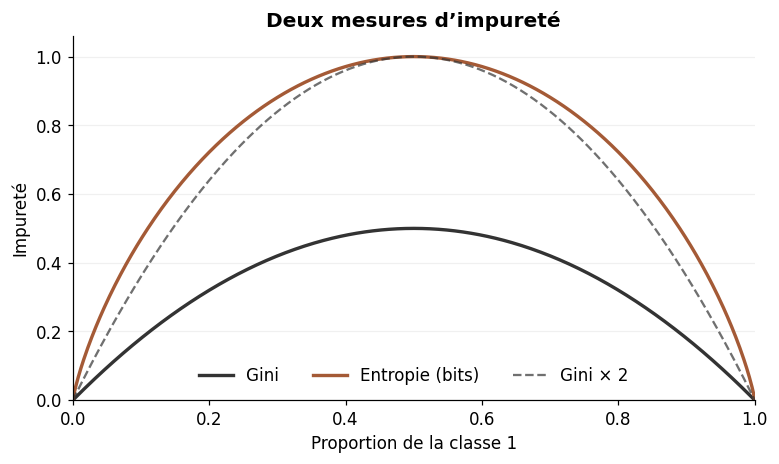

In [2]:
def gini(counts):
    p = np.asarray(counts, dtype=float)/np.sum(counts)
    return 1-np.sum(p**2)

def entropy(counts):
    p = np.asarray(counts, dtype=float)/np.sum(counts)
    p = p[p>0]
    return -np.sum(p*np.log2(p))

p = np.linspace(0,1,501)
g = np.array([gini([q,1-q]) for q in p])
h = np.array([entropy([q,1-q]) for q in p])
fig, ax = plt.subplots(figsize=(8,4.3))
ax.plot(p,g,color=COLORS['gini'],label='Gini',lw=2.2)
ax.plot(p,h,color=COLORS['entropy'],label='Entropie (bits)',lw=2.2)
ax.plot(p,2*g,color=COLORS['gini'],ls='--',alpha=.7,label='Gini × 2')
ax.set(xlabel='Proportion de la classe 1',ylabel='Impureté',xlim=(0,1),ylim=(0,1.06),title='Deux mesures d’impureté')
ax.grid(axis='y',alpha=.18); ax.legend(frameon=False,loc='lower center',ncol=3)
save_figure(fig,'01-impurity-curves')

### Un contre-exemple construit
Un parent de 100 observations contient 50 A et 50 B. Le découpage 1 isole 10 A, le découpage 2 donne deux nœuds de même taille, chacun dominé par une classe. On calcule les impuretés pondérées et on vérifie le choix réel de scikit-learn sur deux variables binaires reproduisant exactement ces découpages.

,découpage,gauche_A_B,droite_A_B,gini_enfants,gini_gain,entropy_enfants,entropy_gain
0,Découpage 1,"[10, 0]","[40, 50]",0.444444,0.055556,0.891968,0.108032
1,Découpage 2,"[34, 16]","[16, 34]",0.435200,0.064800,0.904381,0.095619


gini Découpage 2
entropy Découpage 1


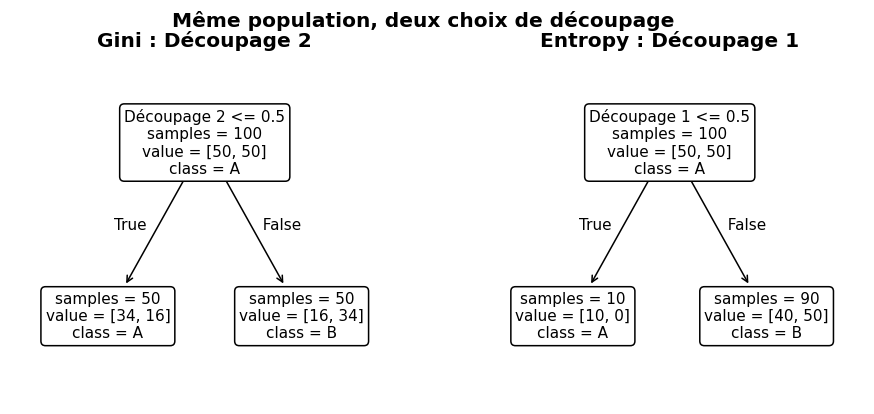

In [3]:
parent=[50,50]
splits={'Découpage 1':([10,0],[40,50]),'Découpage 2':([34,16],[16,34])}
rows=[]
for name,(left,right) in splits.items():
    row={'découpage':name,'gauche_A_B':str(left),'droite_A_B':str(right)}
    for criterion,measure in [('gini',gini),('entropy',entropy)]:
        weighted=(sum(left)*measure(left)+sum(right)*measure(right))/sum(parent)
        row[f'{criterion}_enfants']=weighted
        row[f'{criterion}_gain']=measure(parent)-weighted
    rows.append(row)
example=pd.DataFrame(rows)
save_table(example,'split_example'); display(example.round(6))
y_demo=np.repeat([0,1],50)
X_demo=pd.DataFrame({'Découpage 1':np.ones(100),'Découpage 2':np.ones(100)})
X_demo.loc[:9,'Découpage 1']=0
X_demo.loc[list(range(34))+list(range(50,66)),'Découpage 2']=0
fig,axes=plt.subplots(1,2,figsize=(10,4.1))
for ax,criterion in zip(axes,CRITERIA):
    tree=DecisionTreeClassifier(criterion=criterion,max_depth=1,random_state=SEED).fit(X_demo,y_demo)
    chosen=X_demo.columns[tree.tree_.feature[0]]
    print(criterion,chosen)
    assert chosen==example.loc[example[f'{criterion}_enfants'].idxmin(),'découpage']
    plot_tree(tree,feature_names=list(X_demo.columns),class_names=['A','B'],filled=False,rounded=True,impurity=False,ax=ax,fontsize=10)
    ax.set_title(f'{criterion.capitalize()} : {chosen}')
fig.suptitle('Même population, deux choix de découpage',fontweight='bold')
save_figure(fig,'02-constructed-splits')

## 2. Trois paramètres, deux critères
Dans scikit-learn, `entropy` et `log_loss` appellent la même implémentation. On vérifie le mapping interne (API privée, inspectée uniquement pour cette démonstration).

Dans une feuille $m$, les probabilités prédites sont les fréquences empiriques $p_{mk}$. La log-loss d'entraînement de l'arbre est la moyenne pondérée des entropies des feuilles (multipliée par $\ln 2$ si l'entropie est en bits et la log-loss en logarithmes naturels). Le découpage est glouton : il ne garantit pas l'optimum global de l'arbre. En validation, la log-loss peut être élevée si une feuille pure attribue une probabilité nulle à une classe observée. `sklearn.metrics.log_loss` tronque les probabilités extrêmes.

[Documentation scikit-learn 1.8](https://scikit-learn.org/1.8/modules/tree.html#classification-criteria).

In [4]:
print(_classes.CRITERIA_CLF)
assert _classes.CRITERIA_CLF['entropy'] is _classes.CRITERIA_CLF['log_loss']

{'gini': <class 'sklearn.tree._criterion.Gini'>, 'log_loss': <class 'sklearn.tree._criterion.Entropy'>, 'entropy': <class 'sklearn.tree._criterion.Entropy'>}


## 3. Jeux de données
- Titanic : 891 lignes, 7 variables (Age, Fare, SibSp, Parch, Pclass, Sex, Embarked). Le fichier utilisé est une copie locale fournie avec Gradio, au format du train Kaggle. Il n'a pas été téléchargé ni comparé à l'original pendant cette exécution. Pour reproduire, placer le `train.csv` obtenu sur [Kaggle](https://www.kaggle.com/c/titanic/data) dans `data/titanic.csv` (ou `data/train.csv`). Le fichier brut n'est pas redistribué ; son empreinte SHA-256 est exportée. L'imputation numérique médiane, catégorielle modale et l'encodage one-hot sont ajustés sur chaque partition d'entraînement uniquement. On ne sépare pas les groupes familiaux par fold ; ce protocole ne mesure pas la généralisation à des familles inconnues.
- Breast Cancer Wisconsin, Wine, Digits : jeux intégrés à scikit-learn.
- Deux jeux synthétiques de 3 000 lignes, 20 variables dont 8 informatives et 4 redondantes, `class_sep=0.8`, `flip_y=0.02`, poids demandés 50/50 et 95/5, même graine. Les distributions effectives peuvent différer des poids. Deux réalisations distinctes, non une manipulation causale isolant exclusivement le déséquilibre.

In [5]:
def locate_titanic():
    paths=[Path('data/titanic.csv'),Path('data/train.csv')]
    spec=find_spec('gradio')
    if spec is not None and spec.origin:
        paths.append(Path(spec.origin).parent/'media_assets/data/titanic.csv')
    for path in paths:
        if path.is_file(): return path
    raise FileNotFoundError('Placer le train.csv Titanic de Kaggle dans data/titanic.csv.')

NUM=['Age','Fare','SibSp','Parch']; CAT=['Pclass','Sex','Embarked']
titanic_path=locate_titanic(); titanic=pd.read_csv(titanic_path)
assert len(titanic)==891 and set(NUM+CAT+['Survived']).issubset(titanic.columns)
sha=hashlib.sha256(titanic_path.read_bytes()).hexdigest()
print('Source Titanic :',titanic_path,'SHA-256 :',sha)
save_table(pd.DataFrame([{'source':str(titanic_path),'sha256':sha}]),'titanic_source')
datasets={'Titanic':(titanic[NUM+CAT].copy(),titanic.Survived.to_numpy())}
for name,loader in [('Breast Cancer',load_breast_cancer),('Wine',load_wine),('Digits',load_digits)]:
    b=loader(); datasets[name]=(pd.DataFrame(b.data,columns=b.feature_names),b.target)
for name,weights in [('Synth. équilibré',[.5,.5]),('Synth. déséquilibré',[.95,.05])]:
    X,y=make_classification(n_samples=3000,n_features=20,n_informative=8,n_redundant=4,
        n_clusters_per_class=2,weights=weights,class_sep=.8,flip_y=.02,random_state=SEED)
    datasets[name]=(pd.DataFrame(X,columns=[f'x{i}' for i in range(X.shape[1])]),y)

def prepare(name,X_train,X_val):
    if name!='Titanic':
        return X_train.to_numpy(dtype=np.float32),X_val.to_numpy(dtype=np.float32),list(X_train.columns)
    prep=ColumnTransformer([('num',SimpleImputer(strategy='median'),NUM),
        ('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore',sparse_output=False)),CAT)],verbose_feature_names_out=False)
    return prep.fit_transform(X_train).astype(np.float32),prep.transform(X_val).astype(np.float32),list(prep.get_feature_names_out())

def make_model(family,criterion,seed,depth=None):
    params=dict(criterion=criterion,max_depth=depth,random_state=seed)
    if family=='Arbre': return DecisionTreeClassifier(**params)
    return RandomForestClassifier(**params,n_estimators=N_TREES,n_jobs=1)

def trees(model):
    return [model] if isinstance(model,DecisionTreeClassifier) else model.estimators_

def structure_equal(a,b):
    fields=('children_left','children_right','feature','threshold','value','impurity','n_node_samples','weighted_n_node_samples','missing_go_to_left')
    ta,tb=trees(a),trees(b)
    return len(ta)==len(tb) and all(all(np.array_equal(getattr(x.tree_,f),getattr(y.tree_,f)) for f in fields) for x,y in zip(ta,tb))

inventory=pd.DataFrame([{'dataset':name,'n':len(y),'features':X.shape[1],'classes':len(np.unique(y)),
    'distribution':str(dict(zip(*[a.tolist() for a in np.unique(y,return_counts=True)]))),
    'minority_pct':100*np.min(np.unique(y,return_counts=True)[1])/len(y)} for name,(X,y) in datasets.items()])
save_table(inventory,'datasets'); display(inventory.round(2))

Source Titanic : /opt/pyvenv/lib/python3.13/site-packages/gradio/media_assets/data/titanic.csv SHA-256 : 7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f


,dataset,n,features,classes,distribution,minority_pct
0,Titanic,891,7,2,"{0: 549, 1: 342}",38.38
1,Breast Cancer,569,30,2,"{0: 212, 1: 357}",37.26
2,Wine,178,13,3,"{0: 59, 1: 71, 2: 48}",26.97
3,Digits,1797,64,10,"{0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 18...",9.68
4,Synth. équilibré,3000,20,2,"{0: 1491, 1: 1509}",49.70
5,Synth. déséquilibré,3000,20,2,"{0: 2818, 1: 182}",6.07


### 3.1. Vérification de l'équivalence
Une partition stratifiée 80/20 (graine 42) par dataset. Comparaison exacte des structures de tous les arbres, des prédictions et des probabilités. Test de non-régression, pas une preuve universelle à lui seul.

In [6]:
alias_rows=[]
for name,(X,y) in datasets.items():
    tr,va=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
    Xt,Xv,_=prepare(name,X.iloc[tr],X.iloc[va])
    for family in MODELS:
        e=make_model(family,'entropy',SEED).fit(Xt,y[tr]); l=make_model(family,'log_loss',SEED).fit(Xt,y[tr])
        alias_rows.append({'dataset':name,'model':family,'structure_equal':structure_equal(e,l),
            'predictions_equal':np.array_equal(e.predict(Xv),l.predict(Xv)),
            'probabilities_equal':np.array_equal(e.predict_proba(Xv),l.predict_proba(Xv)),
            'max_abs_proba_delta':np.max(np.abs(e.predict_proba(Xv)-l.predict_proba(Xv)))})
aliases=pd.DataFrame(alias_rows)
assert aliases[['structure_equal','predictions_equal','probabilities_equal']].all().all()
save_table(aliases,'alias_checks'); display(aliases)

,dataset,model,structure_equal,predictions_equal,probabilities_equal,max_abs_proba_delta
0,Titanic,Arbre,True,True,True,0.0
1,Titanic,Forêt,True,True,True,0.0
2,Breast Cancer,Arbre,True,True,True,0.0
3,Breast Cancer,Forêt,True,True,True,0.0
4,Wine,Arbre,True,True,True,0.0
5,Wine,Forêt,True,True,True,0.0
6,Digits,Arbre,True,True,True,0.0
7,Digits,Forêt,True,True,True,0.0
8,Synth. équilibré,Arbre,True,True,True,0.0
9,Synth. équilibré,Forêt,True,True,True,0.0


### 3.2. Deux arbres réels
Exemple fixé avant le benchmark : Titanic, partition stratifiée 80/20, profondeur 2. Les effectifs des nœuds sont ceux de l'entraînement. Les arbres peuvent coïncider : ce serait aussi un résultat.

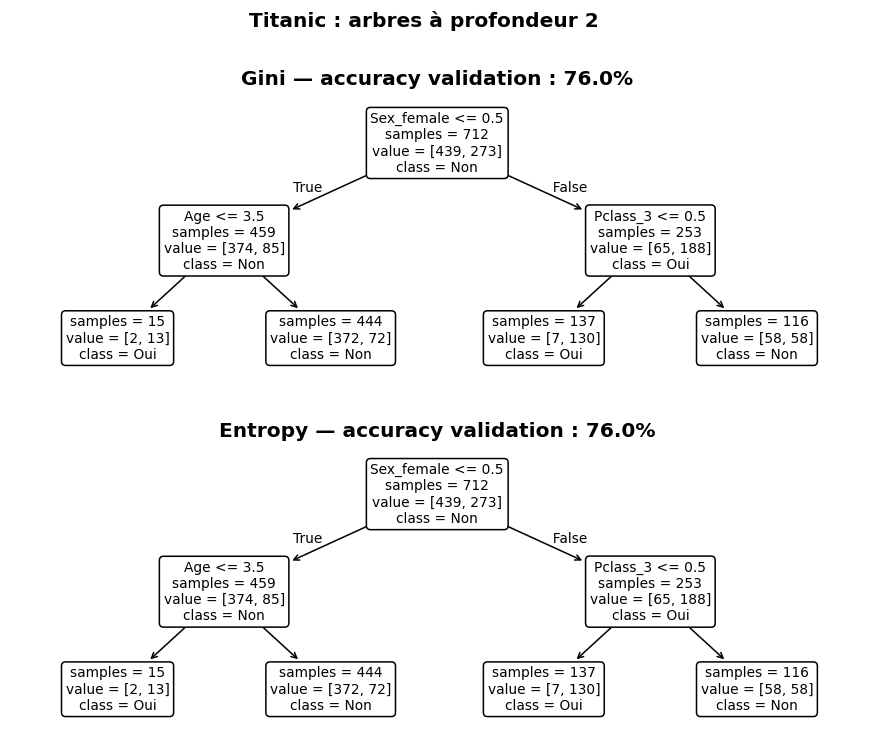

In [7]:
X,y=datasets['Titanic']; tr,va=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
Xt,Xv,names=prepare('Titanic',X.iloc[tr],X.iloc[va])
fig,axes=plt.subplots(2,1,figsize=(10,7.6))
for ax,criterion in zip(axes,CRITERIA):
    m=make_model('Arbre',criterion,SEED,depth=2).fit(Xt,y[tr])
    plot_tree(m,feature_names=names,class_names=['Non','Oui'],filled=False,rounded=True,impurity=False,ax=ax,fontsize=9)
    ax.set_title(f'{criterion.capitalize()} — accuracy validation : {accuracy_score(y[va],m.predict(Xv)):.1%}')
fig.suptitle('Titanic : arbres à profondeur 2',fontweight='bold')
save_figure(fig,'03-titanic-trees')

### 3.3. Benchmark prédictif
5 folds stratifiés, 3 répétitions (15 partitions). Chaque paire voit les mêmes données, le même prétraitement et la même graine (42 + numéro de fold). Autres hyperparamètres par défaut, profondeur non limitée, forêts de 100 arbres avec `n_jobs=1`. Pas d'optimisation des scores absolus. Métriques : accuracy, F1 macro, log-loss (log naturel), profondeur et feuilles (moyennes des arbres pour la forêt), désaccord des prédictions, différence des probabilités et proportion de racines correspondantes identiques (variable et seuil). Chronométrage séparé.

In [8]:
cv_cache={}
for name,(X,y) in datasets.items():
    cv=RepeatedStratifiedKFold(n_splits=N_SPLITS,n_repeats=N_REPEATS,random_state=SEED)
    cv_cache[name]=[]
    for i,(tr,va) in enumerate(cv.split(X,y)):
        Xt,Xv,_=prepare(name,X.iloc[tr],X.iloc[va])
        cv_cache[name].append((i,Xt,Xv,y[tr],y[va]))

def evaluate(family,criterion,seed,depth,Xt,Xv,yt,yv):
    m=make_model(family,criterion,seed,depth).fit(Xt,yt)
    pred,proba=m.predict(Xv),m.predict_proba(Xv); ts=trees(m)
    metrics={'accuracy':accuracy_score(yv,pred),'f1_macro':f1_score(yv,pred,average='macro',zero_division=0),
        'log_loss':log_loss(yv,proba,labels=m.classes_), 'depth':np.mean([t.get_depth() for t in ts]),
        'leaves':np.mean([t.get_n_leaves() for t in ts]),
        'zero_true_proba_rate':np.mean(proba[np.arange(len(yv)),np.searchsorted(m.classes_,yv)]==0)}
    return metrics,pred,proba,m

records,pair_records=[],[]
with threadpool_limits(limits=1):
    for name,folds in cv_cache.items():
        for i,Xt,Xv,yt,yv in folds:
            for family in MODELS:
                outcomes={}
                for criterion in CRITERIA:
                    met,pred,proba,m=evaluate(family,criterion,SEED+i,None,Xt,Xv,yt,yv)
                    outcomes[criterion]=(pred,proba,m)
                    records.append({'dataset':name,'model':family,'fold':i,'repeat':i//N_SPLITS,'criterion':criterion,'n_val':len(yv),**met})
                pg,qg,mg=outcomes['gini']; pe,qe,me=outcomes['entropy']
                pair_records.append({'dataset':name,'model':family,'fold':i,'repeat':i//N_SPLITS,'n_val':len(yv),
                    'disagreement':np.mean(pg!=pe),'mean_abs_proba_delta':np.mean(np.abs(qg-qe)),
                    'same_root_fraction':np.mean([a.tree_.feature[0]==b.tree_.feature[0] and a.tree_.threshold[0]==b.tree_.threshold[0] for a,b in zip(trees(mg),trees(me))])})
        print(name,': terminé',flush=True)
scores=pd.DataFrame(records); pairs=pd.DataFrame(pair_records)
assert len(scores)==len(datasets)*N_SPLITS*N_REPEATS*len(MODELS)*len(CRITERIA)
assert not scores.duplicated(['dataset','model','fold','criterion']).any()
assert len(pairs)*2==len(scores)
save_table(scores,'cv_scores'); save_table(pairs,'cv_pairs')

Titanic : terminé


Breast Cancer : terminé


Wine : terminé


Digits : terminé


Synth. équilibré : terminé


Synth. déséquilibré : terminé


In [9]:
KEYS=['dataset','model']; METRICS=['accuracy','f1_macro','log_loss','depth','leaves','zero_true_proba_rate']
summary=scores.groupby(KEYS+['criterion'],sort=False)[METRICS].agg(['mean','std']).reset_index()
summary.columns=['_'.join(filter(None,col)) for col in summary.columns.to_flat_index()]
save_table(summary,'cv_summary')
wide=scores.pivot(index=KEYS+['fold'],columns='criterion',values=METRICS)
deltas=(wide.xs('entropy',axis=1,level=1)-wide.xs('gini',axis=1,level=1)).add_suffix('_delta').reset_index()
save_table(deltas,'cv_paired_deltas')
comp=deltas.groupby(KEYS,sort=False).mean(numeric_only=True).drop(columns='fold').reset_index()
comp=comp.merge(pairs.groupby(KEYS,sort=False)[['disagreement','mean_abs_proba_delta','same_root_fraction']].mean().reset_index(),on=KEYS)
comp=comp.merge(deltas.groupby(KEYS,sort=False)['accuracy_delta'].agg(entropy_wins=lambda s:(s>1e-12).sum(),ties=lambda s:(s.abs()<=1e-12).sum(),gini_wins=lambda s:(s< -1e-12).sum()).reset_index(),on=KEYS)
save_table(comp,'cv_comparison')
view=comp[KEYS+['accuracy_delta','f1_macro_delta','log_loss_delta','depth_delta','leaves_delta','disagreement','entropy_wins','ties','gini_wins']].copy()
for k in ['accuracy_delta','f1_macro_delta','disagreement']: view[k]*=100
display(view.round(3).rename(columns={'accuracy_delta':'Δ accuracy (pp)','f1_macro_delta':'Δ F1 (pp)','disagreement':'désaccord (%)'}))

,dataset,model,Δ accuracy (pp),Δ F1 (pp),log_loss_delta,depth_delta,leaves_delta,désaccord (%),entropy_wins,ties,gini_wins
0,Breast Cancer,Arbre,0.176,0.182,-0.063,-0.600,-2.000,5.563,8,1,6
1,Breast Cancer,Forêt,0.060,0.057,0.015,-0.377,-1.800,1.112,5,5,5
2,Digits,Arbre,1.002,1.004,-0.361,-3.467,-20.667,19.756,8,1,6
3,Digits,Forêt,0.019,0.016,-0.012,-1.615,-11.799,1.447,6,4,5
4,Synth. déséquilibré,Arbre,0.711,1.752,-0.256,-3.200,-21.467,9.467,10,3,2
5,Synth. déséquilibré,Forêt,-0.078,-1.464,-0.043,-2.946,-13.229,0.300,4,5,6
6,Synth. équilibré,Arbre,0.111,0.113,-0.040,-0.467,-32.533,23.667,6,1,8
7,Synth. équilibré,Forêt,0.444,0.439,-0.008,1.334,-23.562,4.756,10,4,1
8,Titanic,Arbre,-0.264,-0.275,0.107,1.600,-3.267,7.520,6,0,9
9,Titanic,Forêt,0.187,0.205,0.033,0.831,-2.560,1.909,8,3,4


Les écarts sont **entropie moins Gini**. Un point de pourcentage (pp) correspond à 0,01 d'écart absolu des scores. Moyennes non pondérées par fold (tailles presque identiques). Les partitions ne sont pas indépendantes ; les dispersions ne sont ni des intervalles de confiance, ni des tests de significativité.

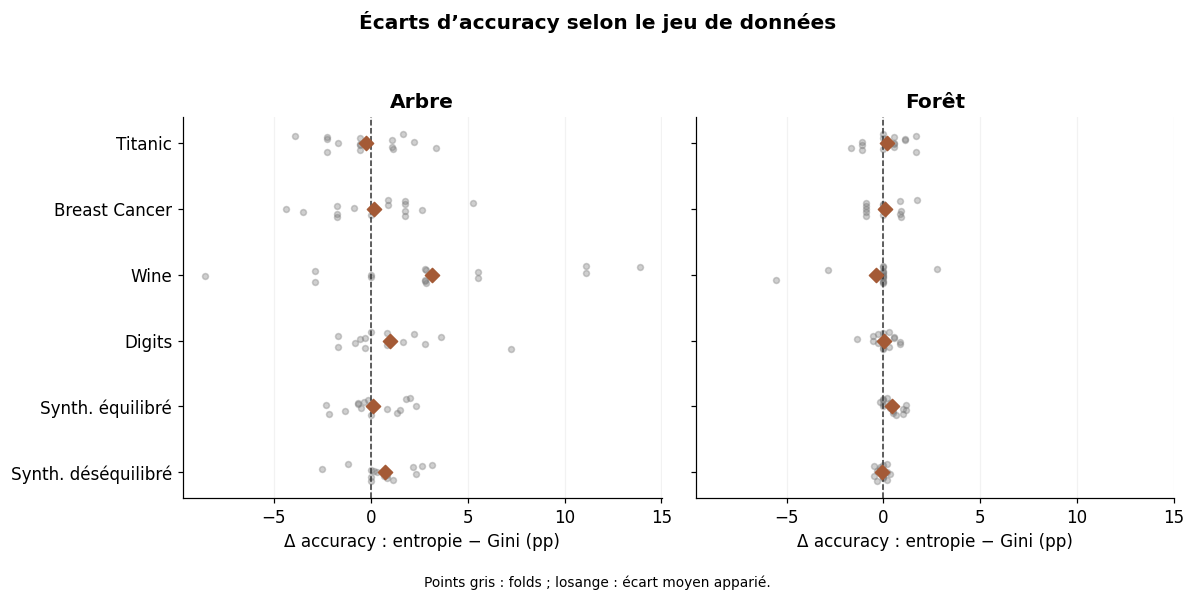

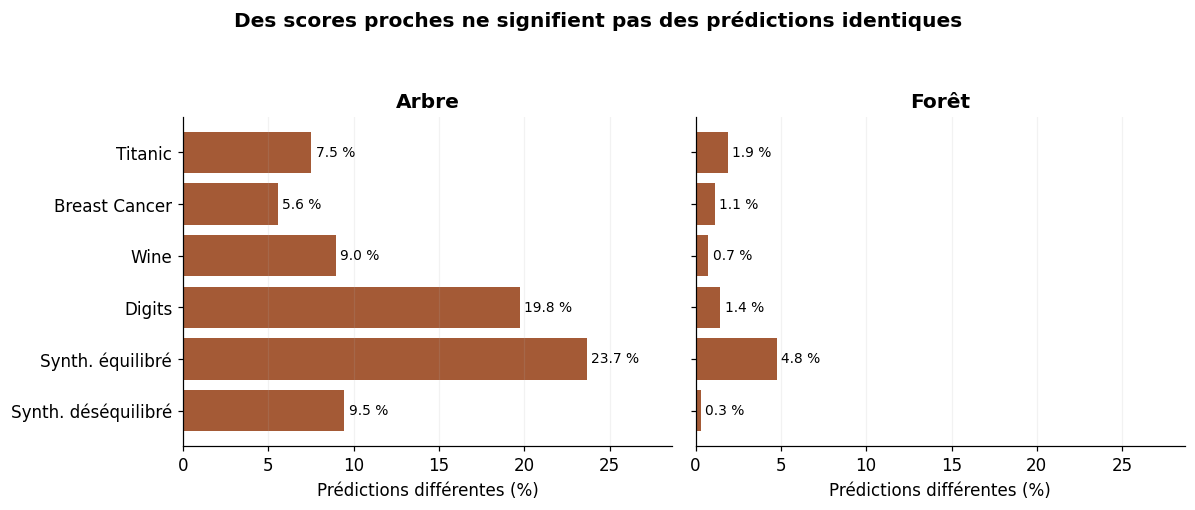

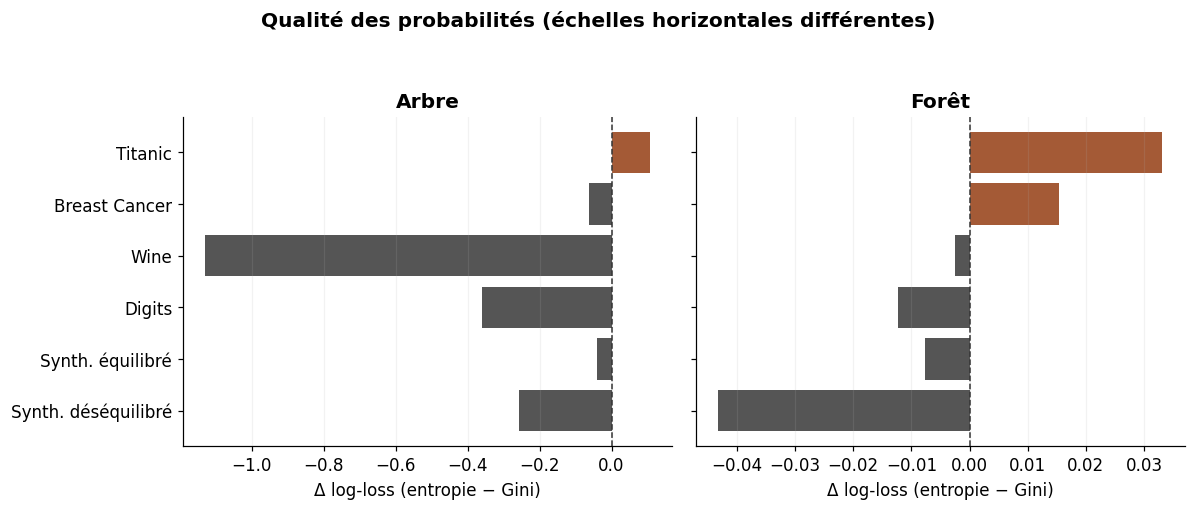

In [10]:
fig,axes=plt.subplots(1,2,figsize=(11,5.4),sharey=True,sharex=True)
for ax,family in zip(axes,MODELS):
    for j,name in enumerate(datasets):
        vals=deltas.loc[(deltas.model==family)&(deltas.dataset==name),'accuracy_delta'].to_numpy()*100
        ax.scatter(vals,j+np.linspace(-.13,.13,len(vals)),s=15,alpha=.35,color='#777777')
        ax.scatter(vals.mean(),j,color=COLORS['entropy'],marker='D',s=43,zorder=3)
    ax.axvline(0,color='#333333',lw=1,ls='--')
    ax.set(title=family,xlabel='Δ accuracy : entropie − Gini (pp)',yticks=range(len(datasets)),yticklabels=list(datasets)); ax.grid(axis='x',alpha=.16)
axes[0].invert_yaxis(); fig.suptitle('Écarts d’accuracy selon le jeu de données',fontweight='bold')
fig.text(.5,.01,'Points gris : folds ; losange : écart moyen apparié.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.04,1,.94)); save_figure(fig,'04-accuracy-deltas')

fig,axes=plt.subplots(1,2,figsize=(11,4.7),sharey=True,sharex=True)
for ax,family in zip(axes,MODELS):
    sub=comp.set_index(['model','dataset']).loc[family].reindex(datasets)
    ax.barh(np.arange(len(sub)),100*sub.disagreement,color=COLORS['entropy'])
    for j,v in enumerate(100*sub.disagreement): ax.text(v+.25,j,f'{v:.1f} %',va='center',fontsize=9)
    ax.set(title=family,xlabel='Prédictions différentes (%)',yticks=range(len(sub)),yticklabels=list(datasets),xlim=(0,max(25,100*comp.disagreement.max()+5))); ax.grid(axis='x',alpha=.16)
axes[0].invert_yaxis(); fig.suptitle('Des scores proches ne signifient pas des prédictions identiques',fontweight='bold')
fig.tight_layout(rect=(0,0,1,.93)); save_figure(fig,'05-prediction-disagreement')

fig,axes=plt.subplots(1,2,figsize=(11,4.7),sharey=True)
for ax,family in zip(axes,MODELS):
    sub=comp.set_index(['model','dataset']).loc[family].reindex(datasets)
    ax.barh(np.arange(len(sub)),sub.log_loss_delta,color=['#a45a36' if v>0 else '#555555' for v in sub.log_loss_delta]); ax.axvline(0,color='#333333',ls='--',lw=1)
    ax.set(title=family,xlabel='Δ log-loss (entropie − Gini)',yticks=range(len(sub)),yticklabels=list(datasets)); ax.grid(axis='x',alpha=.16)
axes[0].invert_yaxis(); fig.suptitle('Qualité des probabilités (échelles horizontales différentes)',fontweight='bold')
fig.tight_layout(rect=(0,0,1,.93)); save_figure(fig,'06-log-loss-deltas')

## 4. Temps d'entraînement
Données synthétiques équilibrées, 20 variables, 1 000, 5 000 et 20 000 observations ; réalisation distincte par taille, identique entre critères. Forêts de 100 arbres, une seule tâche, limitation à un thread. Échauffement préalable sur 500 observations pour chaque famille/critère. Trois répétitions, ordre des critères alterné, même graine, chronométrage de `fit` uniquement (hors génération, création du modèle et prédiction). Médianes et temps bruts exportés. Résultats spécifiques à cette machine et cette configuration, non extrapolables à des forêts parallélisées.

1000 Arbre : terminé


1000 Forêt : terminé


5000 Arbre : terminé


5000 Forêt : terminé


20000 Arbre : terminé


20000 Forêt : terminé


criterion,n,model,entropy,gini,entropy_over_gini
0,1000,Arbre,0.0250,0.0171,1.4605
1,1000,Forêt,1.6485,0.8198,2.0109
2,5000,Arbre,0.1411,0.1469,0.9606
3,5000,Forêt,1.9286,1.8768,1.0276
4,20000,Arbre,0.6824,0.8231,0.8291
5,20000,Forêt,14.5717,11.1591,1.3058


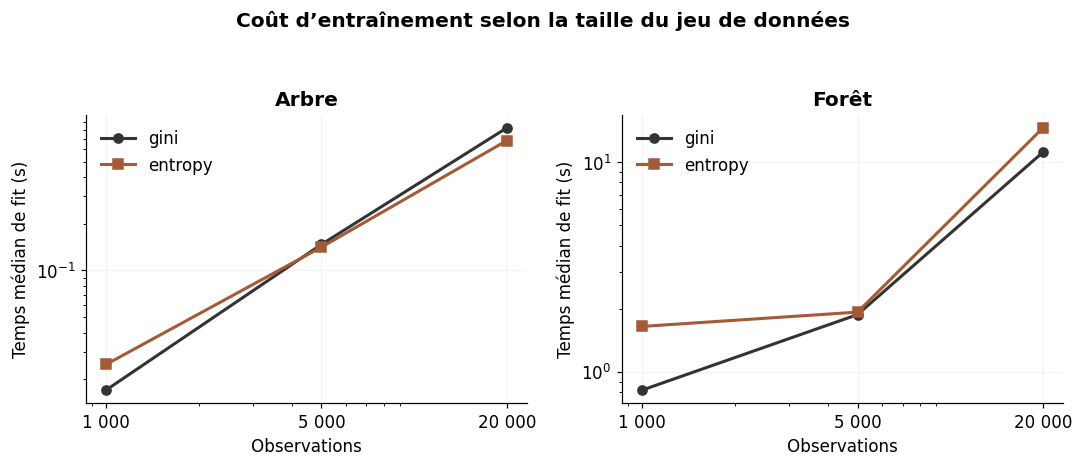

In [11]:
SIZES=[1000,5000,20000]; TIMING_REPS=3

def timing_data(n):
    X,y=make_classification(n_samples=n,n_features=20,n_informative=8,n_redundant=4,class_sep=.8,flip_y=.02,random_state=SEED)
    return np.ascontiguousarray(X,dtype=np.float32),y

timing_rows=[]
with threadpool_limits(limits=1):
    Xw,yw=timing_data(500)
    for family in MODELS:
        for criterion in CRITERIA: make_model(family,criterion,SEED).fit(Xw,yw)
    for j,n in enumerate(SIZES):
        Xt,yt=timing_data(n)
        for k,family in enumerate(MODELS):
            for i in range(TIMING_REPS):
                order=CRITERIA if (i+j+k)%2==0 else CRITERIA[::-1]
                for criterion in order:
                    m=make_model(family,criterion,SEED); t0=perf_counter(); m.fit(Xt,yt); elapsed=perf_counter()-t0
                    timing_rows.append({'n':n,'model':family,'repeat':i,'criterion':criterion,'seconds':elapsed,'mean_leaves':np.mean([t.get_n_leaves() for t in trees(m)])})
            print(n,family,': terminé',flush=True)
timing=pd.DataFrame(timing_rows)
assert len(timing)==len(SIZES)*len(MODELS)*TIMING_REPS*len(CRITERIA)
save_table(timing,'timing_raw')
med=timing.groupby(['n','model','criterion']).seconds.median().unstack().reset_index(); med['entropy_over_gini']=med.entropy/med.gini
save_table(med,'timing_summary'); display(med.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4.3))
for ax,family in zip(axes,MODELS):
    s=med[med.model==family]
    for criterion,marker in [('gini','o'),('entropy','s')]: ax.plot(s.n,s[criterion],color=COLORS[criterion],marker=marker,label=criterion,lw=2)
    ax.set(title=family,xlabel='Observations',ylabel='Temps médian de fit (s)',xscale='log',yscale='log',xticks=SIZES)
    ax.set_xticklabels([f'{n:,}'.replace(',',' ') for n in SIZES]); ax.grid(alpha=.15); ax.legend(frameon=False)
fig.suptitle('Coût d’entraînement selon la taille du jeu de données',fontweight='bold')
fig.tight_layout(rect=(0,0,1,.93)); save_figure(fig,'07-fit-times')

## 5. Faut-il conserver `criterion` dans GridSearchCV ?
Analyse de sensibilité pour les arbres individuels, mêmes folds et graines. `max_depth` parmi 3, 5, 10, 20 et None. Les scores sans limite sont réutilisés. On compare l'amplitude des scores moyens quand la profondeur change (moyennée sur les deux critères) et l'écart absolu moyen entre critères (moyenné sur les cinq profondeurs). Ce résumé dépend de la grille choisie. On ne réalise pas une évaluation indépendante de modèles optimisés.

,dataset,metric,mean_depth_range_pp,mean_criterion_gap_pp,max_criterion_gap_pp
0,Titanic,accuracy,2.132,0.203,0.302
1,Titanic,f1_macro,1.829,0.231,0.409
2,Breast Cancer,accuracy,0.324,0.188,0.296
3,Breast Cancer,f1_macro,0.398,0.175,0.267
4,Wine,accuracy,1.489,2.537,3.132
5,Wine,f1_macro,1.480,2.534,3.137
6,Digits,accuracy,35.670,4.426,12.112
7,Digits,f1_macro,42.696,4.734,12.923
8,Synth. équilibré,accuracy,8.511,0.382,0.789
9,Synth. équilibré,f1_macro,8.797,0.411,0.963


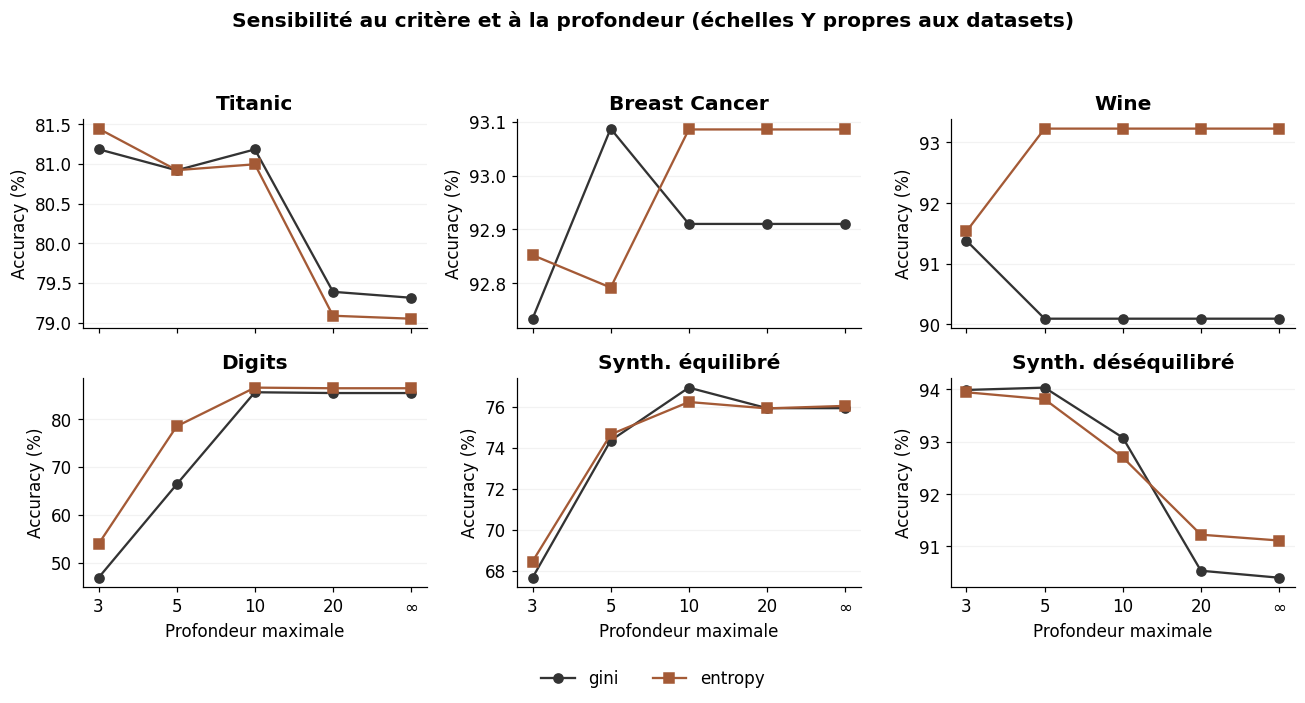

In [12]:
DEPTHS=[3,5,10,20,None]
depth_rows=scores[scores.model=='Arbre'][['dataset','fold','criterion','accuracy','f1_macro']].copy(); depth_rows['max_depth']='None'
depth_records=depth_rows.to_dict('records')
with threadpool_limits(limits=1):
    for name,folds in cv_cache.items():
        for i,Xt,Xv,yt,yv in folds:
            for depth in DEPTHS[:-1]:
                for criterion in CRITERIA:
                    m=make_model('Arbre',criterion,SEED+i,depth).fit(Xt,yt); pred=m.predict(Xv)
                    depth_records.append({'dataset':name,'fold':i,'criterion':criterion,'max_depth':str(depth),'accuracy':accuracy_score(yv,pred),'f1_macro':f1_score(yv,pred,average='macro',zero_division=0)})
depth_scores=pd.DataFrame(depth_records)
assert len(depth_scores)==len(datasets)*N_SPLITS*N_REPEATS*len(CRITERIA)*len(DEPTHS)
save_table(depth_scores,'depth_scores')
means=depth_scores.groupby(['dataset','criterion','max_depth'])[['accuracy','f1_macro']].mean().reset_index(); save_table(means,'depth_summary')
amp_rows=[]
for name in datasets:
    for metric in ['accuracy','f1_macro']:
        s=means[means.dataset==name].pivot(index='max_depth',columns='criterion',values=metric)
        amp_rows.append({'dataset':name,'metric':metric,'mean_depth_range_pp':100*(s.max()-s.min()).mean(),
            'mean_criterion_gap_pp':100*(s.entropy-s.gini).abs().mean(),'max_criterion_gap_pp':100*(s.entropy-s.gini).abs().max()})
amp=pd.DataFrame(amp_rows); save_table(amp,'depth_sensitivity'); display(amp.round(3))
fig,axes=plt.subplots(2,3,figsize=(12,6.4),sharex=True)
order=[str(d) for d in DEPTHS]
for ax,name in zip(axes.flat,datasets):
    sub=means[means.dataset==name]
    for criterion,marker in [('gini','o'),('entropy','s')]:
        z=sub[sub.criterion==criterion].set_index('max_depth').reindex(order)
        ax.plot(range(len(order)),100*z.accuracy,color=COLORS[criterion],marker=marker,label=criterion)
    ax.set(title=name,xticks=range(len(order)),xticklabels=['3','5','10','20','∞'],ylabel='Accuracy (%)'); ax.grid(axis='y',alpha=.16)
for ax in axes[-1]: ax.set_xlabel('Profondeur maximale')
handles,labels=axes[0,0].get_legend_handles_labels(); fig.legend(handles,labels,loc='lower center',ncol=2,frameon=False)
fig.suptitle('Sensibilité au critère et à la profondeur (échelles Y propres aux datasets)',fontweight='bold')
fig.tight_layout(rect=(0,.06,1,.94)); save_figure(fig,'08-depth-sensitivity')

### Résultats observés dans cette exécution

- `entropy` et `log_loss` produisent exactement les mêmes structures et prédictions pour les 12 vérifications.
- Les écarts moyens d'accuracy vont de −0,26 à +3,13 points pour les arbres et de −0,38 à +0,44 point pour les forêts (entropie moins Gini). Wine est un petit jeu de données et ses écarts par fold sont dispersés.
- Sur le synthétique équilibré, deux arbres affichent 75,92 % et 76,03 % d'accuracy mais divergent sur 23,67 % des prédictions. Les désaccords sont moins fréquents pour les forêts sur les six jeux. L'entropie produit moins de feuilles en moyenne dans les 12 combinaisons ; elle n'est pas systématiquement moins profonde.
- Le chronométrage est exploratoire : dispersion du temps mural très élevée, notamment pour les forêts à 1 000 et 20 000 lignes. Reproduire avec davantage de répétitions sur une machine stable avant publication. Pour l'arbre à 20 000 lignes, les trois répétitions donnent néanmoins un temps mural inférieur avec l'entropie sur ce jeu précis.
- Dans la grille de profondeur testée, l'amplitude d'accuracy moyenne due à max_depth est supérieure à l'écart absolu moyen entre critères pour cinq datasets sur six ; Wine est l'exception. Le résultat dépend de la grille.

## 6. Limites et références
Les arbres sans limite de profondeur peuvent surapprendre ; les probabilités extrêmes affectent fortement la log-loss. Les petits jeux classiques et les données synthétiques ne représentent pas tous les problèmes de production. Les folds répétés sont dépendants. Aucun score n'est obtenu sur un test final indépendant. Le chronométrage dépend de la machine, du logiciel et de la configuration. Le test de profondeur ne couvre que les arbres individuels et une grille limitée.

- [scikit-learn 1.8 : arbres de décision](https://scikit-learn.org/1.8/modules/tree.html)
- [DecisionTreeClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [RandomForestClassifier](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [Jeux intégrés](https://scikit-learn.org/1.8/datasets/toy_dataset.html)
- [Kaggle : Titanic](https://www.kaggle.com/c/titanic/data)
- [Quantdare : Decision Trees — Gini vs Entropy](https://quantdare.com/decision-trees-gini-vs-entropy/)